<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/7c_CNN_classification_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Applications – Code I: Image Classification (binary and multi-class)

**Companion to:** *8_CNN_applications_theory* (Sections I and II).

**What we build**

| Part | Task | Data | Model | Tools |
|---|---|---|---|---|
| A | Binary classification | CIFAR-10 *cat vs. dog* | CNN written from scratch | `scikit-learn` metrics: confusion matrix, ROC, PR curves |
| B | Multi-class classification | CIFAR-10 (10 classes) | same CNN, 10 outputs | `scikit-learn` + `torchmetrics` (calibration) |
| C | Explainable AI | Part B model | – | `captum`: saliency, SmoothGrad, Integrated Gradients, Grad-CAM, occlusion |
| D | Transfer learning | CIFAR-10 | **pretrained ResNet-18 (ImageNet)** | `torchvision.models`, `captum` Grad-CAM |

The model (Section 1.3) and the training loop (Section 1.4) are written out explicitly so you can see every step. Everything else uses library functions.

**Dataset:** [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) (Krizhevsky, 2009): 60,000 color images of size 32×32 in 10 classes (50,000 train / 10,000 test). Open access, downloaded automatically by `torchvision`.

**Runtime:** in Colab use *Runtime → Change runtime type → GPU (T4)*. With the default settings the notebook takes roughly 10–15 minutes on a T4 GPU. On a CPU, reduce the sizes in the `CFG` cell.

---

# 0. Setup

In [ ]:
%pip install -q captum torchmetrics

In [ ]:
import copy, random, time, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets
from torchvision import transforms as T
from torchvision.utils import make_grid
from sklearn import metrics

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

warnings.filterwarnings("ignore", category=UserWarning)   # silence library notices (e.g. captum: 'set requires_grad')
set_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda


In [ ]:
plt.rcParams["image.interpolation"] = "nearest"   # show the actual 32x32 pixels (blocky), no smoothing

All sizes that control run time live in one place. Smaller numbers → faster, but lower accuracy.

In [ ]:
CFG = dict(
    batch_size=128,
    val_frac=0.1,            # fraction of the training set held out for validation (model selection, threshold tuning)
    binary_epochs=10,        # Part A
    multi_train_size=25000,  # Part B: number of training images used (max 45,000 after the validation split)
    multi_epochs=15,
    ft_train_size=10000,     # Part D: training images for fine-tuning the pretrained ResNet-18
    ft_img_size=128,         # Part D: images are upsampled 32 -> 128 for the ImageNet backbone
    ft_epochs_head=2,        # Part D, stage 1 (frozen backbone)
    ft_epochs_full=3,        # Part D, stage 2 (fine-tune all layers)
    num_workers=2,
)

# 1. Data

## 1.1 Transforms and data augmentation
* **Normalization**: standardize each channel, $\tilde x_c=(x_c-\mu_c)/\sigma_c$, with the commonly used CIFAR-10 training-set statistics.
* **Training augmentation**: random crop with 4-pixel padding (small translations) + horizontal flip. Both are label preserving for CIFAR-10. (Vertical flips would not be.)
* **Validation / test**: only `ToTensor` + normalization.

In [ ]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # CIFAR-10 training-set statistics

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(MEAN, STD)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

root = "./data"
train_aug = datasets.CIFAR10(root, train=True, download=True, transform=train_tf)    # used for training
train_plain = datasets.CIFAR10(root, train=True, download=True, transform=test_tf)   # same images, no augmentation (validation)
test_set = datasets.CIFAR10(root, train=False, download=True, transform=test_tf)
CLASSES = test_set.classes

# Hold out a validation split from the TRAINING set (the test set is only used once, at the very end)
perm = np.random.default_rng(0).permutation(len(train_aug))
n_val = int(CFG["val_frac"] * len(perm))
val_idx_all, train_idx_all = perm[:n_val], perm[n_val:]
print(f"train {len(train_idx_all)} | val {len(val_idx_all)} | test {len(test_set)}")

def denorm(x, mean=MEAN, std=STD):
    """Undo normalization for display: (3,H,W) tensor -> (H,W,3) numpy in [0,1]."""
    return T.Normalize([-m / s for m, s in zip(mean, std)], [1 / s for s in std])(x.detach().cpu()).clamp(0, 1).permute(1, 2, 0).numpy()

100%|██████████| 170M/170M [13:42<00:00, 207kB/s]


train 45000 | val 5000 | test 10000


## 1.2 A look at the data

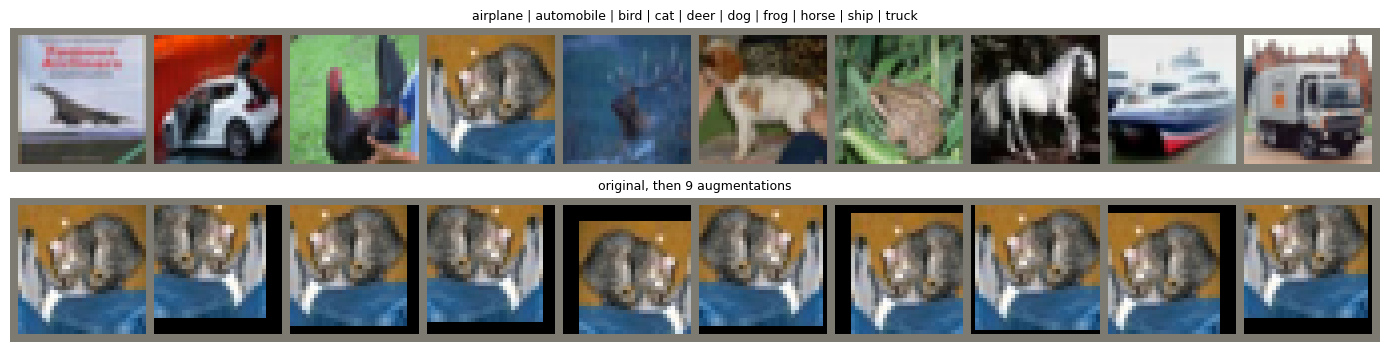

In [ ]:
# One example per class (top) and 9 random augmentations of one cat image (bottom)
targets = np.array(test_set.targets)
examples = torch.stack([test_set[int(np.where(targets == k)[0][0])][0] for k in range(10)])
cat_img = datasets.CIFAR10(root, train=False)[int(np.where(targets == 3)[0][0])][0]      # PIL image
augmented = torch.stack([test_tf(cat_img)] + [train_tf(cat_img) for _ in range(9)])
fig, ax = plt.subplots(2, 1, figsize=(14, 3.6))
for a, imgs, title in [(ax[0], examples, " | ".join(CLASSES)), (ax[1], augmented, "original, then 9 augmentations")]:
    a.imshow(denorm(make_grid(imgs, nrow=10, padding=2))); a.set_title(title, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 1.3 Model (from scratch)
A VGG-style network: three stages of `[conv3×3 → BN → ReLU] × 2`, with max pooling between stages, then global average pooling, dropout and a linear layer. Spatial size: $32\to16\to8$. The last feature map ($256\times8\times8$) is what Grad-CAM will explain in Part C.

The same class serves both tasks: `n_out=1` (binary, one logit) or `n_out=10` (multi-class).

In [ ]:
def conv_bn_relu(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class CifarCNN(nn.Module):
    def __init__(self, n_out=10, widths=(64, 128, 256), p_drop=0.3):
        super().__init__()
        layers, cin = [], 3
        for i, w in enumerate(widths):
            layers += [conv_bn_relu(cin, w), conv_bn_relu(w, w)]
            if i < len(widths) - 1:
                layers.append(nn.MaxPool2d(2))
            cin = w
        self.features = nn.Sequential(*layers)       # (N, 256, 8, 8) for 32x32 input
        self.pool = nn.AdaptiveAvgPool2d(1)          # global average pooling
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(cin, n_out)

    def forward(self, x):
        f = self.features(x)
        return self.fc(self.drop(torch.flatten(self.pool(f), 1)))   # logits

m = CifarCNN(10)
print(m(torch.randn(2, 3, 32, 32)).shape, f"| {sum(p.numel() for p in m.parameters()):,} parameters")

torch.Size([2, 10]) | 1,148,874 parameters


## 1.4 Training loop (written out explicitly)
Each step: **forward** → **loss** → `zero_grad` → **backward** (autograd computes $\nabla_{\boldsymbol\theta}\mathcal{L}$) → **optimizer step**.

* Optimizer: **AdamW** (Adam with decoupled weight decay).
* Learning-rate schedule: **one-cycle** (warm up, then anneal), which trains small CNNs quickly.
* Model selection: keep the weights with the best **validation** metric (a form of early stopping).
* `model.train()` vs `model.eval()`: switches dropout on/off and makes BatchNorm use batch statistics (train) vs. running statistics (eval).

In [ ]:
def make_loader(ds, idx=None, shuffle=False, bs=None):
    ds = ds if idx is None else Subset(ds, idx)
    return DataLoader(ds, batch_size=bs or CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"))

def run_epoch(model, loader, loss_fn, optimizer, scheduler, target_fn):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), target_fn(y.to(device, non_blocking=True))
        logits = model(x)                 # forward pass
        loss = loss_fn(logits, y)         # loss
        optimizer.zero_grad()
        loss.backward()                   # back-propagation
        optimizer.step()                  # parameter update
        scheduler.step()                  # one-cycle schedule is updated every batch
        total += loss.item() * x.size(0); n += x.size(0)
    return total / n

@torch.no_grad()
def predict(model, loader):
    """Return logits and integer labels for a whole loader (on CPU)."""
    model.eval()
    outs, ys = [], []
    for x, y in loader:
        outs.append(model(x.to(device)).float().cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def fit(model, train_loader, val_loader, loss_fn, epochs, lr, target_fn, metric_fn, param_groups=None):
    params = param_groups or [{"params": [p for p in model.parameters() if p.requires_grad], "lr": lr}]
    opt = torch.optim.AdamW(params, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in params],
                                                total_steps=epochs * len(train_loader))
    hist = {"train_loss": [], "val_loss": [], "val_metric": []}
    best_metric, best_state = -np.inf, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = run_epoch(model, train_loader, loss_fn, opt, sched, target_fn)
        logits, y = predict(model, val_loader)
        val_loss = loss_fn(logits, target_fn(y)).item()
        metric = metric_fn(logits, y)
        for k, v in zip(hist, (tr_loss, val_loss, metric)):
            hist[k].append(v)
        if metric > best_metric:
            best_metric, best_state = metric, copy.deepcopy(model.state_dict())
        print(f"epoch {ep:2d} | train loss {tr_loss:.4f} | val loss {val_loss:.4f} | "
              f"val metric {metric:.4f} | {time.time() - t0:.0f}s")
    model.load_state_dict(best_state)
    print(f"restored best model (val metric {best_metric:.4f})")
    return hist

def plot_history(hist, metric_name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
    ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["val_metric"]); ax[1].set_title(f"validation {metric_name}"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

---
# Part A. **Binary classification: cat vs. dog**

Keep only the CIFAR-10 classes *cat* (label 0) and *dog* (label 1), the hardest pair in CIFAR-10.

* Output: one logit $z$; $\hat p=\sigma(z)=\Pr(\text{dog}\mid\mathbf{x})$.
* Loss: `BCEWithLogitsLoss`, i.e., $-[y\log\sigma(z)+(1-y)\log(1-\sigma(z))]$ computed stably from logits.

In [ ]:
CAT, DOG = CLASSES.index("cat"), CLASSES.index("dog")
train_targets, test_targets = np.array(train_aug.targets), np.array(test_set.targets)

bin_train_idx = train_idx_all[np.isin(train_targets[train_idx_all], [CAT, DOG])]
bin_val_idx = val_idx_all[np.isin(train_targets[val_idx_all], [CAT, DOG])]
bin_test_idx = np.where(np.isin(test_targets, [CAT, DOG]))[0]

bin_train_loader = make_loader(train_aug, bin_train_idx, shuffle=True)
bin_val_loader = make_loader(train_plain, bin_val_idx)
bin_test_loader = make_loader(test_set, bin_test_idx)
print(f"binary task: train {len(bin_train_idx)} | val {len(bin_val_idx)} | test {len(bin_test_idx)}")

to_binary = lambda y: (y == DOG).float().unsqueeze(1)          # dog -> 1, cat -> 0; shape (N,1) like the logits
binary_acc = lambda logits, y: metrics.accuracy_score((y == DOG).numpy(), (logits[:, 0] > 0).numpy())   # z > 0  <=>  p > 0.5

binary task: train 9022 | val 978 | test 2000


epoch  1 | train loss 0.6685 | val loss 0.6279 | val metric 0.6503 | 7s
epoch  2 | train loss 0.5895 | val loss 1.9833 | val metric 0.5276 | 4s
epoch  3 | train loss 0.5338 | val loss 0.4960 | val metric 0.7464 | 4s
epoch  4 | train loss 0.4777 | val loss 1.4718 | val metric 0.5624 | 4s
epoch  5 | train loss 0.4495 | val loss 0.8727 | val metric 0.6411 | 4s
epoch  6 | train loss 0.4160 | val loss 0.5993 | val metric 0.7505 | 4s
epoch  7 | train loss 0.3770 | val loss 0.4356 | val metric 0.7873 | 4s
epoch  8 | train loss 0.3467 | val loss 0.3351 | val metric 0.8579 | 4s
epoch  9 | train loss 0.3076 | val loss 0.3449 | val metric 0.8517 | 4s
epoch 10 | train loss 0.2937 | val loss 0.3108 | val metric 0.8712 | 4s
restored best model (val metric 0.8712)


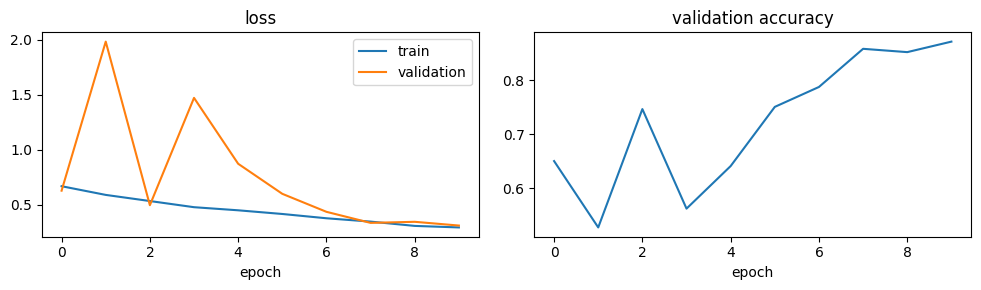

In [ ]:
set_seed(0)
bin_model = CifarCNN(n_out=1).to(device)
bin_hist = fit(bin_model, bin_train_loader, bin_val_loader, nn.BCEWithLogitsLoss(),
               epochs=CFG["binary_epochs"], lr=2e-3, target_fn=to_binary, metric_fn=binary_acc)
plot_history(bin_hist, "accuracy")

## A.1 Evaluation metrics with `scikit-learn`
Definitions are in the Theory notebook, Section I.4. `sklearn.metrics` computes all of them from the true labels and the predicted probabilities (or hard predictions at a threshold).

In [ ]:
logits, y = predict(bin_model, bin_test_loader)
p_test = torch.sigmoid(logits[:, 0]).numpy()          # predicted P(dog)
y_test = (y == DOG).int().numpy()
yhat_test = (p_test >= 0.5).astype(int)               # threshold 0.5

print(metrics.classification_report(y_test, yhat_test, target_names=["cat", "dog"], digits=3))
tn, fp, fn, tp = metrics.confusion_matrix(y_test, yhat_test).ravel()
print(f"specificity = TN/(TN+FP) = {tn / (tn + fp):.3f}")
print(f"AUROC = {metrics.roc_auc_score(y_test, p_test):.3f} | AP (PR-AUC) = {metrics.average_precision_score(y_test, p_test):.3f}")

              precision    recall  f1-score   support

         cat      0.861     0.857     0.859      1000
         dog      0.858     0.862     0.860      1000

    accuracy                          0.860      2000
   macro avg      0.860     0.859     0.859      2000
weighted avg      0.860     0.860     0.859      2000

specificity = TN/(TN+FP) = 0.857
AUROC = 0.937 | AP (PR-AUC) = 0.940


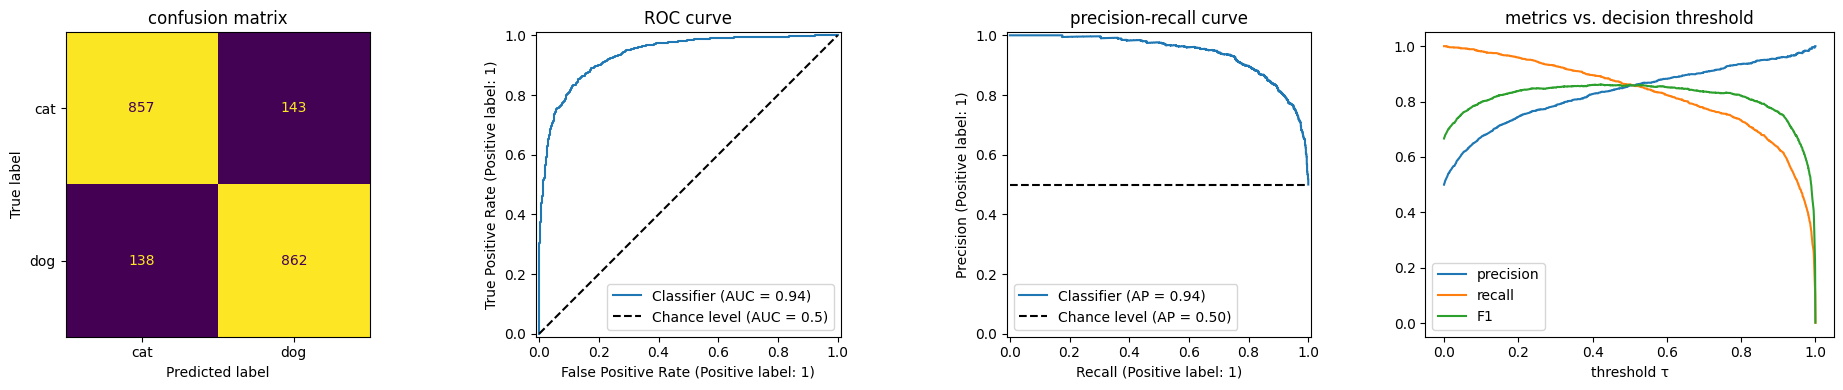

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
metrics.ConfusionMatrixDisplay.from_predictions(y_test, yhat_test, display_labels=["cat", "dog"], ax=ax[0], colorbar=False)
metrics.RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], plot_chance_level=True)
metrics.PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[2], plot_chance_level=True)
prec, rec, thr = metrics.precision_recall_curve(y_test, p_test)
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
ax[3].plot(thr, prec[:-1], label="precision"); ax[3].plot(thr, rec[:-1], label="recall"); ax[3].plot(thr, f1[:-1], label="F1")
ax[3].set(xlabel="threshold τ", title="metrics vs. decision threshold"); ax[3].legend()
ax[0].set_title("confusion matrix"); ax[1].set_title("ROC curve"); ax[2].set_title("precision-recall curve")
plt.tight_layout(); plt.show()

**Choosing the threshold.** Raising $\tau$ trades recall for precision. The threshold is a *decision*, not a model parameter: choose it on the **validation** set for the cost structure of the application (e.g., in defect inspection a missed defect—FN—may cost much more than a false alarm), then report test performance at that fixed threshold.

In [ ]:
val_logits, val_y = predict(bin_model, bin_val_loader)
p_val, y_val = torch.sigmoid(val_logits[:, 0]).numpy(), (val_y == DOG).int().numpy()
prec, rec, thr = metrics.precision_recall_curve(y_val, p_val)
best_thr = thr[np.argmax((2 * prec * rec / np.maximum(prec + rec, 1e-12))[:-1])]
print(f"threshold maximizing validation F1: {best_thr:.2f}")
print(metrics.classification_report(y_test, (p_test >= best_thr).astype(int), target_names=["cat", "dog"], digits=3))

threshold maximizing validation F1: 0.32
              precision    recall  f1-score   support

         cat      0.908     0.762     0.829      1000
         dog      0.795     0.923     0.854      1000

    accuracy                          0.843      2000
   macro avg      0.852     0.843     0.841      2000
weighted avg      0.852     0.843     0.841      2000



---
# Part B. **Multi-class classification: all 10 CIFAR-10 classes**

* Output: 10 logits $\mathbf z$; $\hat{\mathbf p}=\text{softmax}(\mathbf z)$.
* Loss: cross-entropy with **label smoothing** $\varepsilon=0.1$.
* Training subset of `CFG['multi_train_size']` images to keep training short.

multi-class task: train 25000 | val 5000 | test 10000
epoch  1 | train loss 1.7500 | val loss 1.6963 | val metric 0.4726 | 11s
epoch  2 | train loss 1.4705 | val loss 1.6196 | val metric 0.5138 | 11s
epoch  3 | train loss 1.3337 | val loss 1.6457 | val metric 0.5208 | 11s
epoch  4 | train loss 1.2277 | val loss 1.6857 | val metric 0.5330 | 11s
epoch  5 | train loss 1.1316 | val loss 1.2599 | val metric 0.6826 | 11s
epoch  6 | train loss 1.0582 | val loss 1.1869 | val metric 0.7196 | 11s
epoch  7 | train loss 1.0031 | val loss 1.1642 | val metric 0.7388 | 11s
epoch  8 | train loss 0.9546 | val loss 1.0850 | val metric 0.7710 | 11s
epoch  9 | train loss 0.9135 | val loss 1.0135 | val metric 0.7952 | 11s
epoch 10 | train loss 0.8701 | val loss 0.9456 | val metric 0.8214 | 11s
epoch 11 | train loss 0.8302 | val loss 0.9035 | val metric 0.8460 | 11s
epoch 12 | train loss 0.7980 | val loss 0.8767 | val metric 0.8630 | 11s
epoch 13 | train loss 0.7700 | val loss 0.8596 | val metric 0.8694 | 1

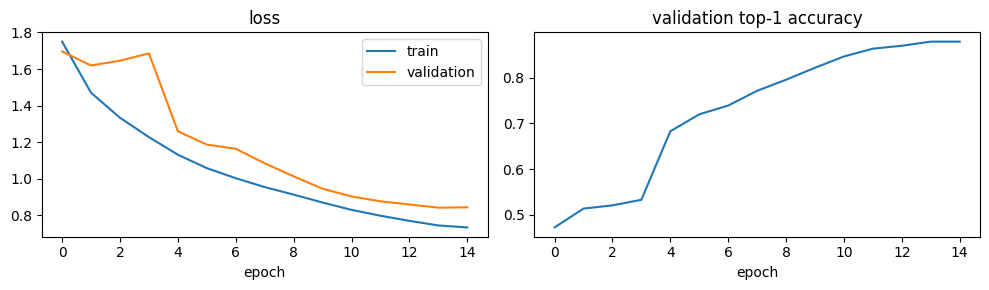

In [ ]:
multi_train_idx = train_idx_all[:CFG["multi_train_size"]]
train_loader = make_loader(train_aug, multi_train_idx, shuffle=True)
val_loader = make_loader(train_plain, val_idx_all)
test_loader = make_loader(test_set)
print(f"multi-class task: train {len(multi_train_idx)} | val {len(val_idx_all)} | test {len(test_set)}")

identity = lambda y: y
top1 = lambda logits, y: metrics.accuracy_score(y.numpy(), logits.argmax(1).numpy())

set_seed(0)
model = CifarCNN(n_out=10).to(device)
hist = fit(model, train_loader, val_loader, nn.CrossEntropyLoss(label_smoothing=0.1),
           epochs=CFG["multi_epochs"], lr=3e-3, target_fn=identity, metric_fn=top1)
plot_history(hist, "top-1 accuracy")

## B.1 Metrics: top-k accuracy, per-class report, macro-F1, confusion matrix

top-1 0.8752 | top-3 0.9784 | macro-F1 0.8747

              precision    recall  f1-score   support

    airplane      0.846     0.899     0.872      1000
  automobile      0.948     0.952     0.950      1000
        bird      0.833     0.822     0.827      1000
         cat      0.784     0.746     0.765      1000
        deer      0.860     0.890     0.875      1000
         dog      0.830     0.795     0.812      1000
        frog      0.895     0.917     0.906      1000
       horse      0.909     0.883     0.896      1000
        ship      0.910     0.925     0.918      1000
       truck      0.932     0.923     0.928      1000

    accuracy                          0.875     10000
   macro avg      0.875     0.875     0.875     10000
weighted avg      0.875     0.875     0.875     10000



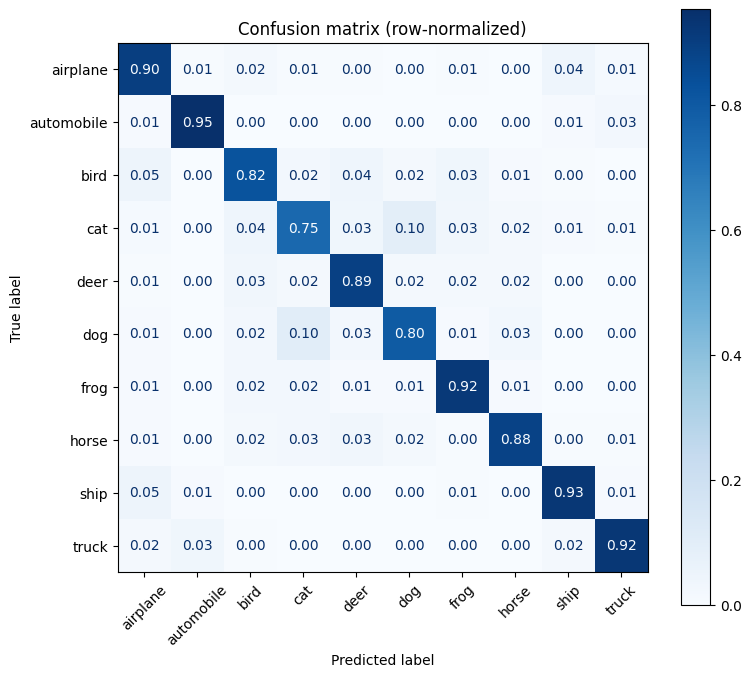

In [ ]:
test_logits, test_y = predict(model, test_loader)
test_prob = test_logits.softmax(1)
y_np, yhat_np = test_y.numpy(), test_logits.argmax(1).numpy()

print(f"top-1 {metrics.accuracy_score(y_np, yhat_np):.4f} | "
      f"top-3 {metrics.top_k_accuracy_score(y_np, test_prob.numpy(), k=3, labels=range(10)):.4f} | "
      f"macro-F1 {metrics.f1_score(y_np, yhat_np, average='macro'):.4f}\n")
print(metrics.classification_report(y_np, yhat_np, target_names=CLASSES, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
metrics.ConfusionMatrixDisplay.from_predictions(y_np, yhat_np, display_labels=CLASSES, normalize="true",
                                                values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("Confusion matrix (row-normalized)"); plt.tight_layout(); plt.show()

## B.2 Calibration: is the confidence trustworthy?
**Expected Calibration Error** $\text{ECE}=\sum_{m}\frac{|B_m|}{N}|\text{acc}(B_m)-\text{conf}(B_m)|$ (`torchmetrics`), and the **reliability diagram** (`sklearn.calibration.calibration_curve`, applied to "was the top prediction correct?" vs. its confidence). A calibrated model lies on the diagonal.

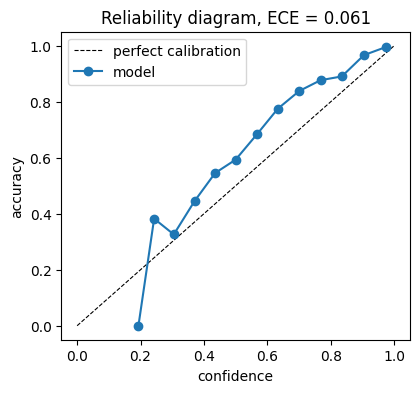

In [ ]:
from torchmetrics.classification import MulticlassCalibrationError
from sklearn.calibration import calibration_curve

ece = MulticlassCalibrationError(num_classes=10, n_bins=15, norm="l1")(test_prob, test_y).item()
conf, pred = test_prob.max(1)
frac_correct, mean_conf = calibration_curve((pred == test_y).numpy(), conf.numpy(), n_bins=15)
plt.figure(figsize=(4.5, 4))
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
plt.plot(mean_conf, frac_correct, "o-", label="model")
plt.xlabel("confidence"); plt.ylabel("accuracy"); plt.title(f"Reliability diagram, ECE = {ece:.3f}"); plt.legend()
plt.show()

---
# Part C. **Explainable AI with `captum`**

[Captum](https://captum.ai) (by Meta) implements the attribution methods of Theory Section I.6. All methods explain the **logit** $S_c$ of a target class $c$ (`target=c`) and return an attribution tensor; `visualize_image_attr` overlays it on the image.

| Method | Captum class | Main argument |
|---|---|---|
| Vanilla gradient | `Saliency` | – |
| SmoothGrad | `NoiseTunnel(Saliency)` | `nt_type="smoothgrad"`, `stdevs` |
| Integrated Gradients | `IntegratedGradients` | `baselines`, `n_steps` |
| Grad-CAM | `LayerGradCam` | the conv layer to explain |
| Occlusion | `Occlusion` | `sliding_window_shapes`, `strides` |

In [ ]:
from captum.attr import Saliency, NoiseTunnel, IntegratedGradients, LayerGradCam, LayerAttribution, Occlusion
from captum.attr import visualization as viz

model.eval()
correct_idx = np.where(yhat_np == y_np)[0]
demo_idx = np.random.default_rng(1).choice(correct_idx, size=4, replace=False)

def get_image(i, ds=test_set):
    x, y = ds[i]
    return x.unsqueeze(0).to(device), y

def to_hwc(attr):
    """captum attribution (1,C,H,W) -> numpy (H,W,C) for visualize_image_attr."""
    return attr[0].detach().cpu().permute(1, 2, 0).numpy()

def gradcam(model, layer, x, target, forward_func=None):
    """Grad-CAM upsampled to the input size, as (1,1,H,W)."""
    cam = LayerGradCam(forward_func or model, layer).attribute(x, target=target, relu_attributions=True)
    return LayerAttribution.interpolate(cam, x.shape[-2:], interpolate_mode="bilinear")

def overlay(ax, attr, img, sign="absolute_value"):
    """Blend a captum attribution (1,C,H,W) over an image; an all-zero map (nothing to show) leaves the image plain."""
    a = to_hwc(attr)
    if np.abs(a).max() > 0:
        viz.visualize_image_attr(a, img, method="blended_heat_map", sign=sign, alpha_overlay=0.5, cmap="jet",
                                 plt_fig_axis=(ax.figure, ax), use_pyplot=False)
    else:
        ax.imshow(img)
    ax.axis("off")

def show_attributions(images, columns, sign="absolute_value", mean=MEAN, std=STD):
    """images: list of (x, y); columns: dict title -> function(x, y) returning a captum attribution (1,C,H,W)."""
    fig, axes = plt.subplots(len(images), 1 + len(columns), figsize=(2.4 * (1 + len(columns)), 2.4 * len(images)), squeeze=False)
    for r, (x, y) in enumerate(images):
        img = denorm(x[0], mean, std)
        axes[r, 0].imshow(img); axes[r, 0].axis("off"); axes[r, 0].set_title(CLASSES[y], fontsize=9)
        for c, (title, fn) in enumerate(columns.items(), start=1):
            overlay(axes[r, c], fn(x, y), img, sign)
            axes[r, c].set_title(title, fontsize=9)
    plt.tight_layout(); plt.show()

images = [get_image(i) for i in demo_idx]

## C.1 Gradient-based: saliency, SmoothGrad, Integrated Gradients, Grad-CAM
* Integrated Gradients uses a **black-image baseline**; `return_convergence_delta=True` returns the error of the **completeness** axiom $\sum_k\text{IG}_k - (S_c(\mathbf x)-S_c(\mathbf x'))$, which should be close to 0.
* Grad-CAM explains the output of `model.features` (the $256\times8\times8$ map from Section 1.3).

IG completeness error: 0.0021


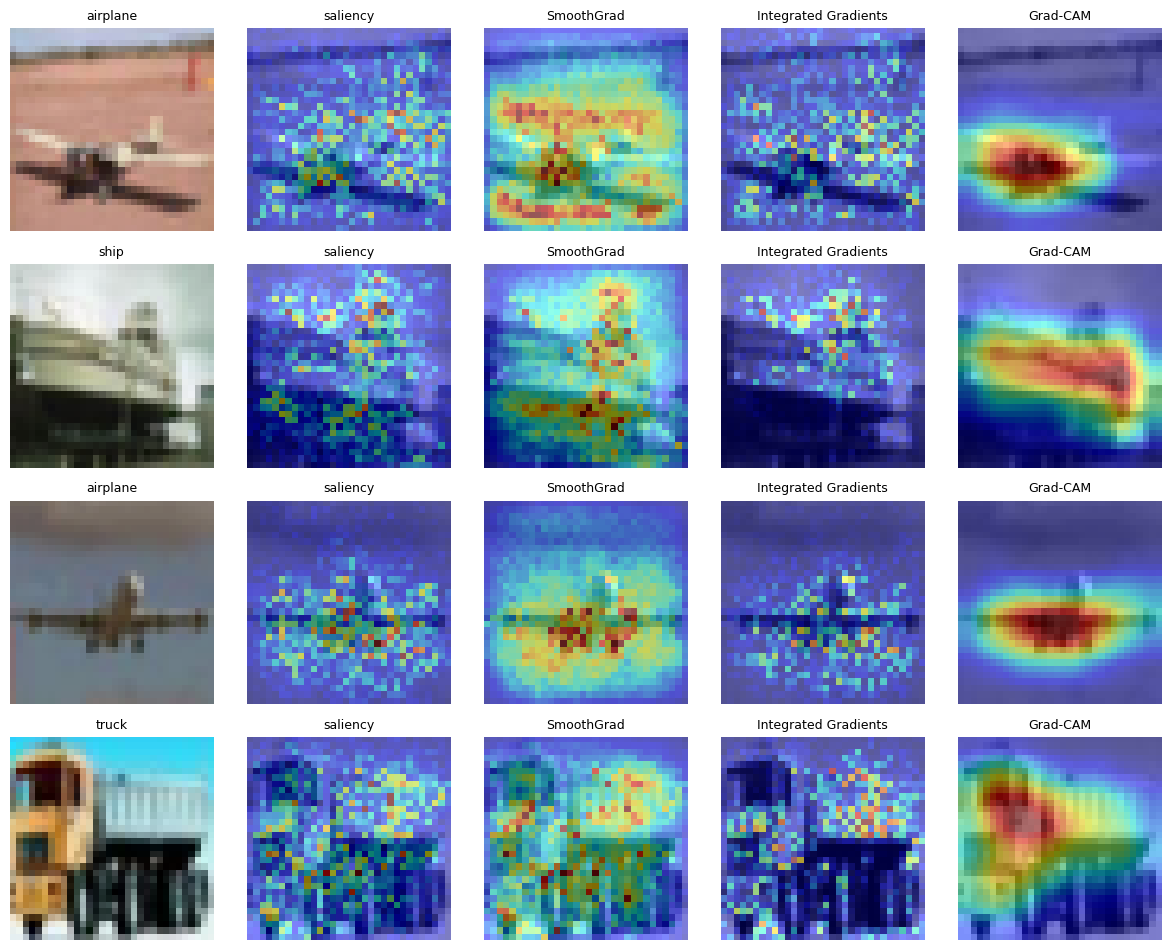

In [ ]:
black = ((torch.zeros(3) - torch.tensor(MEAN)) / torch.tensor(STD)).view(1, 3, 1, 1).to(device)   # black image, normalized
saliency, smoothgrad, ig = Saliency(model), NoiseTunnel(Saliency(model)), IntegratedGradients(model)

x, y = images[0]
_, delta = ig.attribute(x, baselines=black.expand_as(x), target=y, n_steps=64, return_convergence_delta=True)
print(f"IG completeness error: {delta.item():.4f}")

show_attributions(images, {
    "saliency": lambda x, y: saliency.attribute(x, target=y),
    "SmoothGrad": lambda x, y: smoothgrad.attribute(x, nt_type="smoothgrad", nt_samples=32, stdevs=0.15, target=y),
    "Integrated Gradients": lambda x, y: ig.attribute(x, baselines=black.expand_as(x), target=y, n_steps=64),
    "Grad-CAM": lambda x, y: gradcam(model, model.features, x, y),
})

## C.2 Occlusion sensitivity (black-box)
Slide an $8\times8$ patch filled with the dataset mean (0 after normalization) with stride 2 and record the drop in the class **probability** (we pass a softmax-wrapped model as `forward_func`).

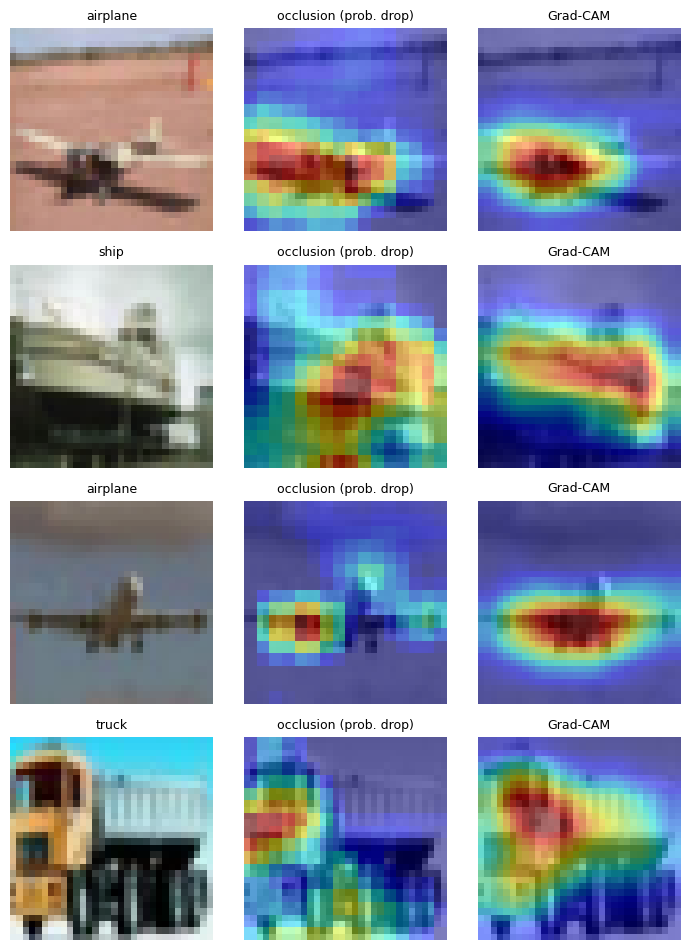

In [ ]:
occlusion = Occlusion(lambda x: model(x).softmax(1))
show_attributions(images, {
    "occlusion (prob. drop)": lambda x, y: occlusion.attribute(x, target=y, sliding_window_shapes=(3, 8, 8),
                                                               strides=(3, 2, 2), baselines=0),
    "Grad-CAM": lambda x, y: gradcam(model, model.features, x, y),
}, sign="positive")

## C.3 Contrastive Grad-CAM and error analysis
For the most confident **mistakes**, show Grad-CAM for the predicted class and for the true class. What did the model look at when it got it wrong?

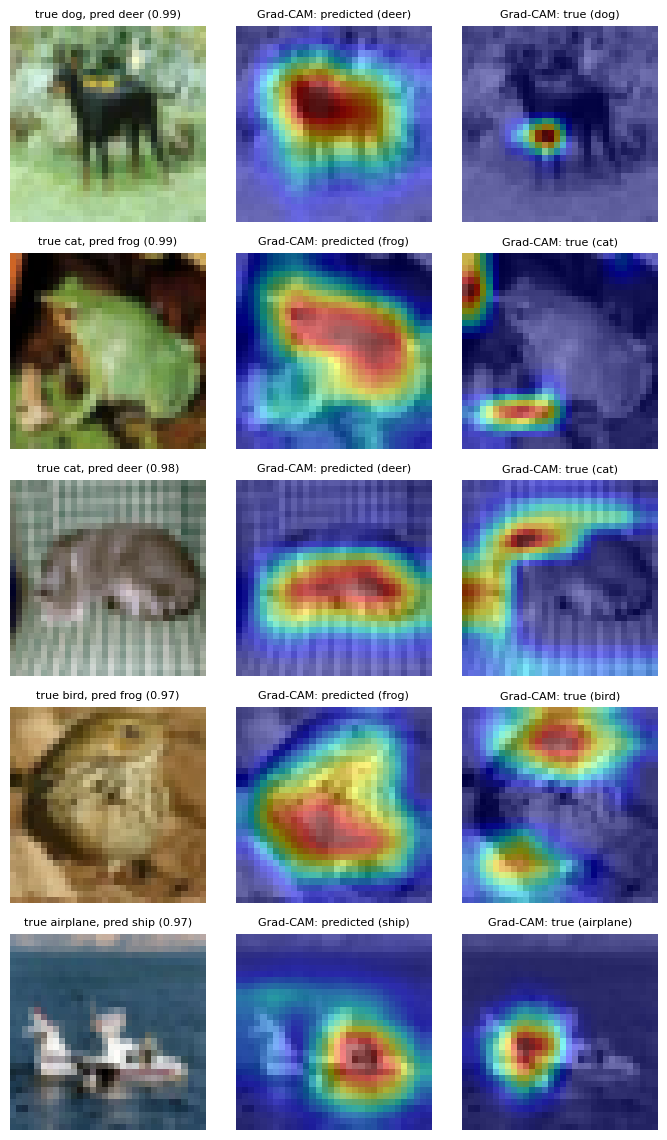

In [ ]:
wrong = np.where(yhat_np != y_np)[0]
conf_wrong = wrong[np.argsort(-test_prob[wrong].max(1).values.numpy())][:5]
fig, axes = plt.subplots(len(conf_wrong), 3, figsize=(7, 2.3 * len(conf_wrong)), squeeze=False)
for r, i in enumerate(conf_wrong):
    x, y = get_image(i)
    pred, img = yhat_np[i], denorm(x[0])
    axes[r, 0].imshow(img); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"true {CLASSES[y]}, pred {CLASSES[pred]} ({test_prob[i, pred]:.2f})", fontsize=8)
    for c, (k, name) in enumerate([(pred, "predicted"), (y, "true")], start=1):
        overlay(axes[r, c], gradcam(model, model.features, x, int(k)), img, "positive")
        axes[r, c].set_title(f"Grad-CAM: {name} ({CLASSES[k]})", fontsize=8)
plt.tight_layout(); plt.show()

## C.4 Sanity check for explanations (Adebayo et al., 2018)
If an explanation reflects what the model *learned*, it must change when the weights are randomized. Compare Grad-CAM maps of the trained model with those of the same architecture with **random weights** (low correlation = passes the check).

In [ ]:
rand_model = CifarCNN(10).to(device).eval()            # same architecture, untrained
with np.errstate(invalid="ignore"):   # an all-zero map has no variance -> correlation undefined (reported as 0)
    corrs = [np.corrcoef(gradcam(model, model.features, x, y).flatten().detach().cpu(),
                         gradcam(rand_model, rand_model.features, x, y).flatten().detach().cpu())[0, 1] for x, y in images]
print("correlation of Grad-CAM (trained vs. random weights):", np.round(np.nan_to_num(corrs), 2))

correlation of Grad-CAM (trained vs. random weights): [-0.02  0.52  0.21  0.45]


## C.5 What did the network learn? First-layer filters and feature maps
* `make_grid(..., normalize=True, scale_each=True)` displays the 64 first-layer $3\times3$ RGB filters.
* `torchvision.models.feature_extraction.create_feature_extractor` returns intermediate outputs by layer name, no hooks needed.

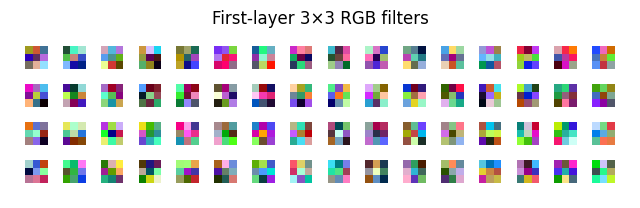

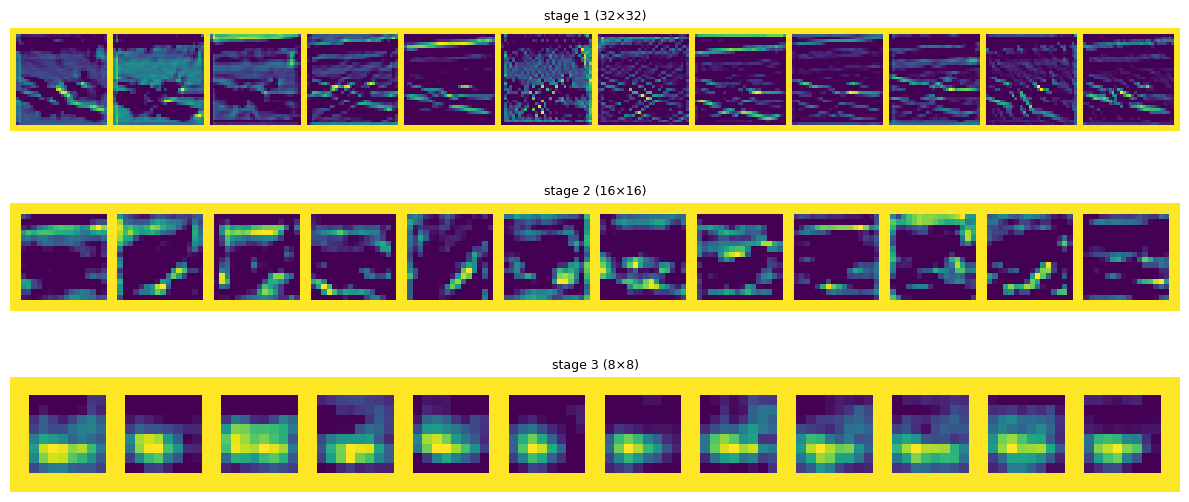

In [ ]:
from torchvision.models.feature_extraction import create_feature_extractor

W1 = model.features[0][0].weight.detach().cpu()              # (64, 3, 3, 3)
plt.figure(figsize=(8, 2.4))
plt.imshow(make_grid(W1, nrow=16, normalize=True, scale_each=True, pad_value=1).permute(1, 2, 0))
plt.axis("off"); plt.title("First-layer 3×3 RGB filters"); plt.show()

extractor = create_feature_extractor(model, return_nodes={"features.1": "stage 1 (32×32)", "features.4": "stage 2 (16×16)",
                                                          "features.7": "stage 3 (8×8)"})
x, y = images[0]
with torch.no_grad():
    feats = extractor(x)
fig, axes = plt.subplots(len(feats), 1, figsize=(12, 1.9 * len(feats)))
for a, (name, f) in zip(axes, feats.items()):
    top = f[0].mean((1, 2)).argsort(descending=True)[:12]      # 12 most active channels
    a.imshow(make_grid(f[0, top].unsqueeze(1).cpu(), nrow=12, normalize=True, scale_each=True, pad_value=1)[0], cmap="viridis")
    a.set_title(name, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## C.6 Binary model: which pixels say "dog", which say "cat"?
The binary model has a single logit $z$ (`target=0`). Grad-CAM on $S=z$ highlights evidence for **dog**; Grad-CAM on $S=-z$ (pass `forward_func=lambda x: -bin_model(x)`) highlights evidence for **cat**.

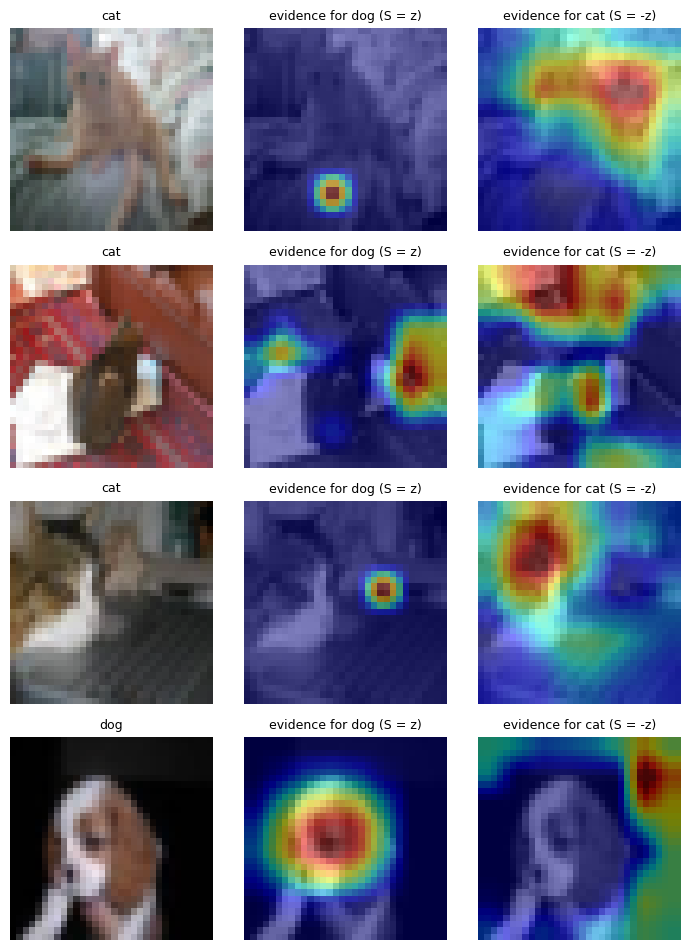

In [ ]:
bin_model.eval()
sel = bin_test_idx[np.random.default_rng(3).choice(len(bin_test_idx), 4, replace=False)]
show_attributions([get_image(i) for i in sel], {
    "evidence for dog (S = z)": lambda x, y: gradcam(bin_model, bin_model.features, x, 0),
    "evidence for cat (S = -z)": lambda x, y: gradcam(bin_model, bin_model.features, x, 0, forward_func=lambda t: -bin_model(t)),
}, sign="positive")

---
# Part D. **Transfer learning with a pretrained ResNet-18**

ResNet-18 pretrained on ImageNet-1k (1.28M images, 1000 classes, $224\times224$ input). Two adjustments for CIFAR-10:
1. **Input size and normalization**: upsample $32\to128$ and normalize with the **ImageNet** mean/std (the statistics the backbone was trained with; available from `weights.transforms()`).
2. **Head**: replace the 1000-way `fc` layer by a new 10-way layer.

Training in two stages (Theory notebook, Section I.5 ii):
* **Stage 1 – feature extraction:** freeze the backbone, train only the new head.
* **Stage 2 – fine-tuning:** unfreeze everything; backbone learning rate 10× smaller than the head's.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
IMAGENET_MEAN, IMAGENET_STD = weights.transforms().mean, weights.transforms().std
IMG = CFG["ft_img_size"]

ft_train_tf = T.Compose([T.Resize(IMG), T.RandomCrop(IMG, padding=IMG // 8), T.RandomHorizontalFlip(),
                         T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
ft_test_tf = T.Compose([T.Resize(IMG), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

ft_train_set = datasets.CIFAR10(root, train=True, transform=ft_train_tf)
ft_val_set = datasets.CIFAR10(root, train=True, transform=ft_test_tf)
ft_test_set = datasets.CIFAR10(root, train=False, transform=ft_test_tf)

ft_train_loader = make_loader(ft_train_set, train_idx_all[:CFG["ft_train_size"]], shuffle=True, bs=64)
ft_val_loader = make_loader(ft_val_set, val_idx_all, bs=256)
ft_test_loader = make_loader(ft_test_set, bs=256)

net = resnet18(weights=weights)
print("ImageNet head:", net.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


ImageNet head: Linear(in_features=512, out_features=1000, bias=True)


## D.1 What does the pretrained model "see" before any training?
Many CIFAR classes have ImageNet counterparts (dog breeds, "tabby cat", "sports car", "container ship"). `weights.meta["categories"]` holds the 1000 ImageNet class names.

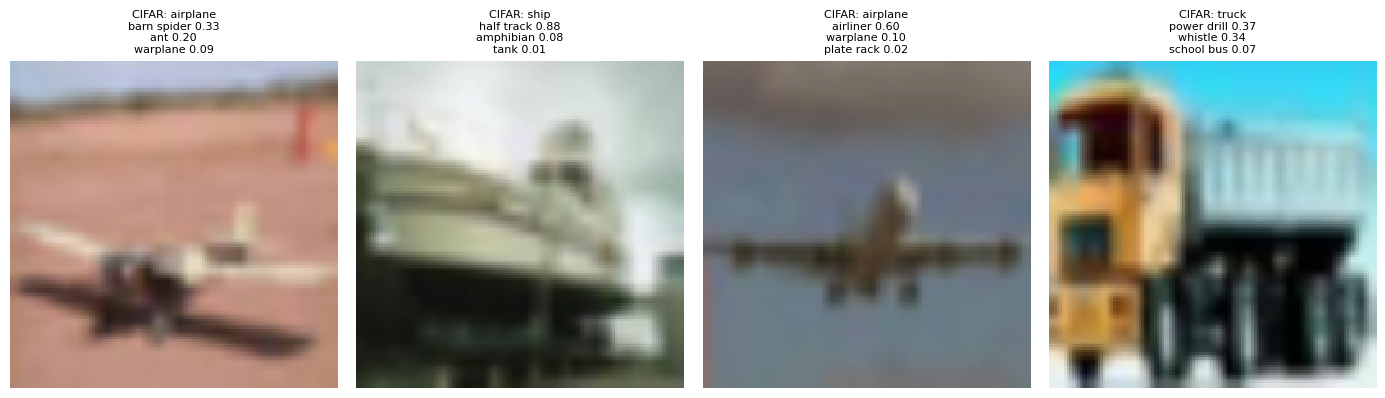

In [ ]:
net = net.to(device).eval()
categories = weights.meta["categories"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
with torch.no_grad():
    for a, i in zip(axes, demo_idx):
        x, y = ft_test_set[i]
        top = net(x.unsqueeze(0).to(device)).softmax(1)[0].cpu().topk(3)
        a.imshow(denorm(x, IMAGENET_MEAN, IMAGENET_STD)); a.axis("off")
        a.set_title(f"CIFAR: {CLASSES[y]}\n" + "\n".join(f"{categories[k][:18]} {p:.2f}" for p, k in zip(top.values, top.indices)),
                    fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Stage 1: feature extraction (frozen backbone, new head)
set_seed(0)
for p in net.parameters():
    p.requires_grad = False
net.fc = nn.Linear(net.fc.in_features, 10)            # new layers have requires_grad=True by default
net = net.to(device)
print(f"trainable parameters: {sum(p.numel() for p in net.parameters() if p.requires_grad):,}")
ft_hist1 = fit(net, ft_train_loader, ft_val_loader, nn.CrossEntropyLoss(label_smoothing=0.1),
               epochs=CFG["ft_epochs_head"], lr=1e-3, target_fn=identity, metric_fn=top1)

trainable parameters: 5,130
epoch  1 | train loss 1.8539 | val loss 1.3177 | val metric 0.6726 | 13s
epoch  2 | train loss 1.3045 | val loss 1.2798 | val metric 0.6812 | 13s
restored best model (val metric 0.6812)


In [ ]:
# Stage 2: fine-tune all layers with discriminative learning rates
for p in net.parameters():
    p.requires_grad = True
head_params = list(net.fc.parameters())
backbone_params = [p for n, p in net.named_parameters() if not n.startswith("fc.")]
print(f"trainable parameters: {sum(p.numel() for p in net.parameters()):,}")
ft_hist2 = fit(net, ft_train_loader, ft_val_loader, nn.CrossEntropyLoss(label_smoothing=0.1),
               epochs=CFG["ft_epochs_full"], lr=None, target_fn=identity, metric_fn=top1,
               param_groups=[{"params": backbone_params, "lr": 1e-4}, {"params": head_params, "lr": 1e-3}])

trainable parameters: 11,181,642
epoch  1 | train loss 1.0578 | val loss 0.8628 | val metric 0.8724 | 15s
epoch  2 | train loss 0.7924 | val loss 0.7578 | val metric 0.9146 | 15s
epoch  3 | train loss 0.6864 | val loss 0.7415 | val metric 0.9206 | 15s
restored best model (val metric 0.9206)


In [ ]:
ft_logits, ft_y = predict(net, ft_test_loader)
ft_pred = ft_logits.argmax(1).numpy()
print(f"{'model':<45}{'train imgs':>11}{'top-1':>8}{'macro-F1':>10}")
print(f"{'CNN from scratch (Part B)':<45}{CFG['multi_train_size']:>11}"
      f"{metrics.accuracy_score(y_np, yhat_np):>8.4f}{metrics.f1_score(y_np, yhat_np, average='macro'):>10.4f}")
print(f"{'ResNet-18 pretrained on ImageNet, fine-tuned':<45}{CFG['ft_train_size']:>11}"
      f"{metrics.accuracy_score(ft_y.numpy(), ft_pred):>8.4f}{metrics.f1_score(ft_y.numpy(), ft_pred, average='macro'):>10.4f}")

model                                         train imgs   top-1  macro-F1
CNN from scratch (Part B)                          25000  0.8752    0.8747
ResNet-18 pretrained on ImageNet, fine-tuned       10000  0.9114    0.9107


## D.2 Grad-CAM on the fine-tuned ResNet-18
ResNet-18 downsamples by 32, so at $128\times128$ input `layer4` is only $4\times4$, while `layer3` is $8\times8$. Deeper layers are more class-specific but coarser; this resolution/semantics trade-off is inherent to Grad-CAM. (For more CAM variants—Grad-CAM++, Score-CAM, Eigen-CAM—see the `pytorch-grad-cam` package.)

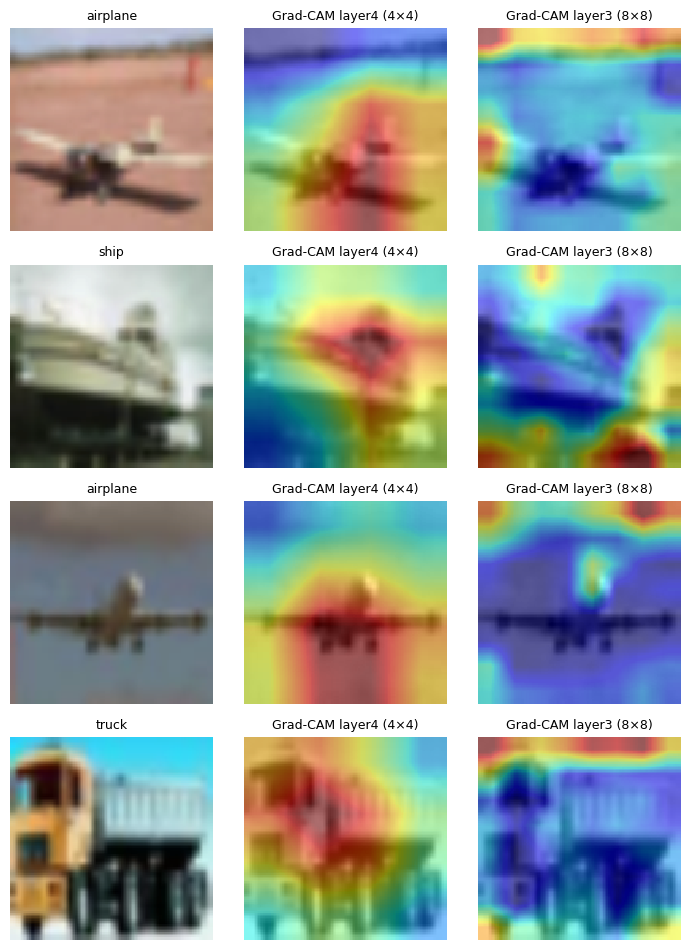

In [ ]:
net.eval()
show_attributions([get_image(i, ft_test_set) for i in demo_idx], {
    "Grad-CAM layer4 (4×4)": lambda x, y: gradcam(net, net.layer4, x, y),
    "Grad-CAM layer3 (8×8)": lambda x, y: gradcam(net, net.layer3, x, y),
}, sign="positive", mean=IMAGENET_MEAN, std=IMAGENET_STD)

---
# Summary and exercises

**Summary**
* The same CNN body serves binary and multi-class classification; only the number of outputs and the loss change (BCE vs. CE).
* Accuracy alone is not enough: use the confusion matrix, precision/recall/F1, ROC and PR curves, macro-averages, and check calibration.
* Gradient-based XAI (saliency, IG, Grad-CAM) needs one or a few backward passes; perturbation methods (occlusion) are model-agnostic but cost many forward passes. Always sanity-check explanations.
* A pretrained ResNet-18 fine-tuned on fewer images typically beats a CNN trained from scratch on more images.

**Exercises**
1. *Class imbalance.* Re-run Part A keeping only 10% of the dog training images. Compare plain BCE with `BCEWithLogitsLoss(pos_weight=...)` using recall, F1 and AP (not accuracy).
2. *Augmentation ablation.* Train Part B without `RandomCrop`/`RandomHorizontalFlip`. How do the train/validation loss curves change?
3. *Depthwise separable convolutions.* Replace the $3\times3$ convolutions in `CifarCNN` by the depthwise separable block from the theory notebook. Compare parameter count and accuracy.
4. *Feature extraction only.* Skip stage 2 in Part D. How much does fine-tuning the backbone add?
5. *Other backbones.* Swap ResNet-18 for `efficientnet_b0` or `mobilenet_v3_large` (`torchvision.models`). Hint: the head is `model.classifier[-1]`.
6. *XAI faithfulness.* Use Captum's `captum.metrics.infidelity` and `sensitivity_max` to compare saliency, Integrated Gradients and Grad-CAM.